<a href="https://colab.research.google.com/github/Alphaoumarsow4/Alpha-s-/blob/main/Alpha_Sow_AI_Threat_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Load the NSL-KDD network intrusion dataset

url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt"

columns = [
    "duration", "protocol_type", "service", "flag",
    "src_bytes", "dst_bytes", "land", "wrong_fragment",
    "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted",
    "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate",
    "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    "attack_type", "difficulty"
]

df = pd.read_csv(url, names=columns)

print("Dataset loaded successfully!")
print("Total rows and columns:", df.shape)

display(df.head())


Dataset loaded successfully!
Total rows and columns: (125973, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack_type,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


Types of Network Protocols:
protocol_type
tcp     102689
udp      14993
icmp      8291
Name: count, dtype: int64

Top 10 Network Attack Types:
attack_type
normal         67343
neptune        41214
satan           3633
ipsweep         3599
portsweep       2931
smurf           2646
nmap            1493
back             956
teardrop         892
warezclient      890
Name: count, dtype: int64

Normal vs Suspicious Activities:
threat
0    67343
1    58630
Name: count, dtype: int64


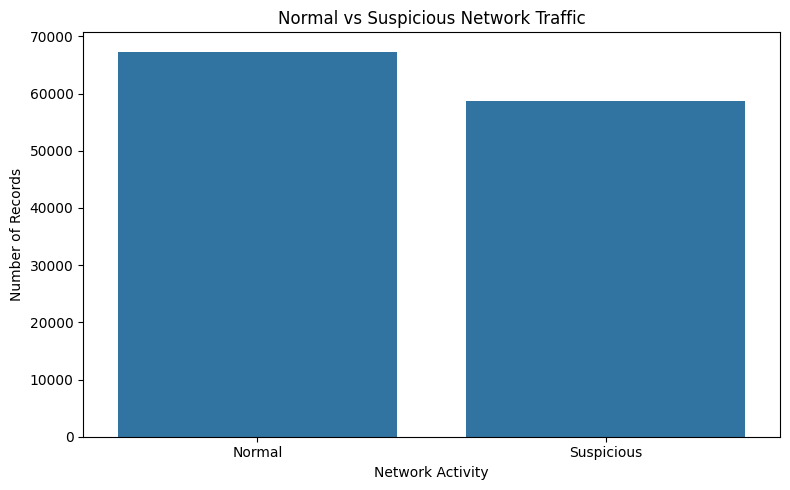

In [3]:

# Explore network activities and attacks

print("Types of Network Protocols:")
print(df["protocol_type"].value_counts())

print("\nTop 10 Network Attack Types:")
print(df["attack_type"].value_counts().head(10))

# Classify activity as normal or suspicious
df["threat"] = (df["attack_type"] != "normal").astype(int)

print("\nNormal vs Suspicious Activities:")
print(df["threat"].value_counts())

# Create a chart
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="threat")

plt.xticks([0, 1], ["Normal", "Suspicious"])
plt.title("Normal vs Suspicious Network Traffic")
plt.xlabel("Network Activity")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()


In [4]:

# Check for missing and corrupted data
print("Missing values before cleaning:", df.isnull().sum().sum())

# Replace invalid values and remove incomplete records
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna().drop_duplicates().copy()

print("Missing values after cleaning:", df.isnull().sum().sum())

# Recreate the threat labels
df["threat"] = (df["attack_type"] != "normal").astype(int)

# Separate network features from threat labels
X = df.drop(columns=["attack_type", "difficulty", "threat"])
y = df["threat"]

# Convert text categories into numbers for machine learning
X = pd.get_dummies(
    X,
    columns=["protocol_type", "service", "flag"],
    dtype=int
)

print("Cleaned dataset shape:", df.shape)
print("Number of AI model features:", X.shape[1])
print("Data cleaning completed successfully!")


Missing values before cleaning: 0
Missing values after cleaning: 0
Cleaned dataset shape: (125973, 44)
Number of AI model features: 122
Data cleaning completed successfully!


In [5]:

# Split the dataset into training and testing groups
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create the Random Forest AI model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the AI threat detector
model.fit(X_train, y_train)

print("AI Threat Detector trained successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


AI Threat Detector trained successfully!
Training records: 100778
Testing records: 25195


In [6]:

# Test the AI threat detector

y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("AI Threat Detection Results")
print("---------------------------")
print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Show detailed performance
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Suspicious"]
))


AI Threat Detection Results
---------------------------
Model Accuracy: 99.90%

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     13469
  Suspicious       1.00      1.00      1.00     11726

    accuracy                           1.00     25195
   macro avg       1.00      1.00      1.00     25195
weighted avg       1.00      1.00      1.00     25195



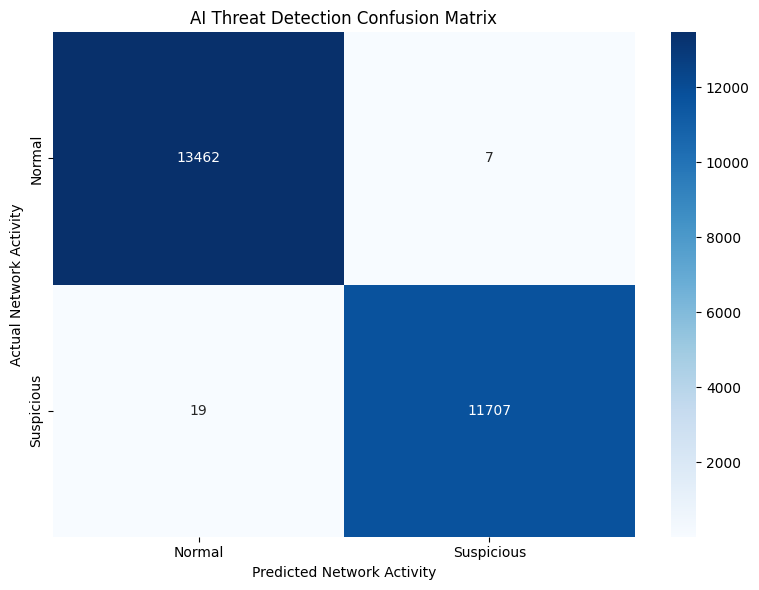

Confusion matrix created successfully!
False alarms: 7
Missed threats: 19


In [7]:

# Create a confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Suspicious"],
    yticklabels=["Normal", "Suspicious"]
)

plt.title("AI Threat Detection Confusion Matrix")
plt.xlabel("Predicted Network Activity")
plt.ylabel("Actual Network Activity")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()

print("Confusion matrix created successfully!")
print("False alarms:", cm[0, 1])
print("Missed threats:", cm[1, 0])


Top 10 Most Common Network Attacks:
attack_type
neptune        41214
satan           3633
ipsweep         3599
portsweep       2931
smurf           2646
nmap            1493
back             956
teardrop         892
warezclient      890
pod              201
Name: count, dtype: int64


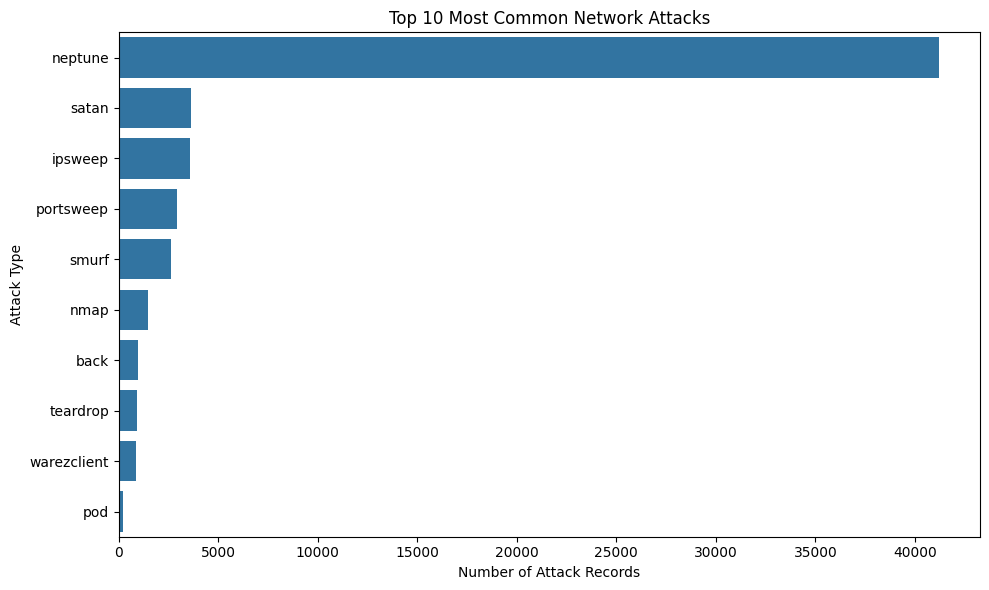

Attack analysis completed successfully!


In [8]:

# Identify the most common network attacks

attacks = df[df["attack_type"] != "normal"]

top_attacks = attacks["attack_type"].value_counts().head(10)

print("Top 10 Most Common Network Attacks:")
print(top_attacks)

# Create a chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_attacks.values,
    y=top_attacks.index
)

plt.title("Top 10 Most Common Network Attacks")
plt.xlabel("Number of Attack Records")
plt.ylabel("Attack Type")

plt.tight_layout()
plt.savefig("top_attacks.png", dpi=200)
plt.show()

print("Attack analysis completed successfully!")


Top 10 Most Important AI Features:
src_bytes                   0.150879
flag_SF                     0.082093
dst_bytes                   0.081333
logged_in                   0.064416
dst_host_same_srv_rate      0.062897
dst_host_srv_count          0.055734
same_srv_rate               0.052708
dst_host_srv_serror_rate    0.040237
diff_srv_rate               0.040128
protocol_type_icmp          0.031164
dtype: float64


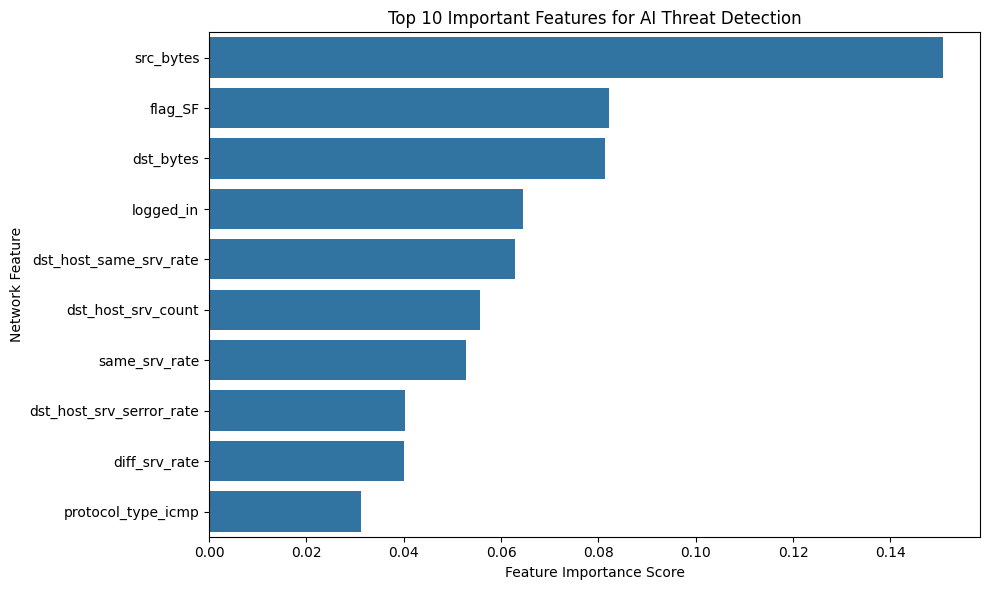

Feature importance analysis completed successfully!


In [9]:

# Identify the most important network features

feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

top_features = feature_importance.head(10)

print("Top 10 Most Important AI Features:")
print(top_features)

# Create a feature importance chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_features.values,
    y=top_features.index
)

plt.title("Top 10 Important Features for AI Threat Detection")
plt.xlabel("Feature Importance Score")
plt.ylabel("Network Feature")

plt.tight_layout()
plt.savefig("feature_importance.png", dpi=200)
plt.show()

print("Feature importance analysis completed successfully!")
